In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn

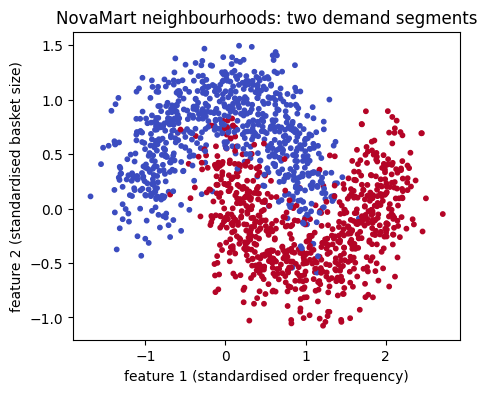

In [ ]:

np.random.seed(7)
torch.manual_seed(7)

# Simulated neighbourhood demand data: two engineered features, non-linear boundary
X, y = make_moons(n_samples=1500, noise=0.25, random_state=7)

plt.figure(figsize=(5,4))
plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", s=10)
plt.title("NovaMart neighbourhoods: two demand segments")
plt.xlabel("feature 1 (standardised order frequency)")
plt.ylabel("feature 2 (standardised basket size)")
plt.show()

In [ ]:
#Step 1 Standardize


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
def build_model():
    model = nn.Sequential(
        nn.Linear(2, 16),
        nn.ReLU(),

        nn.Linear(16, 16),
        nn.ReLU(),

        nn.Linear(16, 1),
        nn.Sigmoid()
    )

    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    return model

In [ ]:
torch.manual_seed(7)

model_vanilla = build_model()

criterion = nn.BCELoss()
optimizer = torch.optim.SGD(
    model_vanilla.parameters(),
    lr=0.05
)

In [ ]:
history_vanilla = {
    "loss": [],
    "val_loss": []
}

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

In [ ]:
history_vanilla["accuracy"] = []
history_vanilla["val_accuracy"] = []

for epoch in range(15):
    model_vanilla.train()

    permutation = torch.randperm(X_train_tensor.size(0))

    epoch_loss = 0.0
    correct_train = 0

    for i in range(0, X_train_tensor.size(0), 64):
        indices = permutation[i:i + 64]

        X_batch = X_train_tensor[indices]
        y_batch = y_train_tensor[indices]

        optimizer.zero_grad()

        y_pred = model_vanilla(X_batch)
        loss = criterion(y_pred, y_batch)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(indices)

        # Track training accuracy
        preds = (y_pred >= 0.5).float()
        correct_train += (preds == y_batch).sum().item()

    epoch_loss /= X_train_tensor.size(0)
    train_acc = correct_train / X_train_tensor.size(0)

    model_vanilla.eval()

    with torch.no_grad():
        y_val_pred = model_vanilla(X_test_tensor)
        val_loss = criterion(y_val_pred, y_test_tensor).item()

        # Track validation accuracy
        val_preds = (y_val_pred >= 0.5).float()
        val_acc = (val_preds == y_test_tensor).sum().item() / X_test_tensor.size(0)

    history_vanilla["loss"].append(epoch_loss)
    history_vanilla["val_loss"].append(val_loss)
    history_vanilla["accuracy"].append(train_acc)
    history_vanilla["val_accuracy"].append(val_acc)

In [ ]:
history_vanilla

{'loss': [0.5759194485346476,
  0.46084540724754336,
  0.3914314846197764,
  0.35028029084205625,
  0.32821268518765767,
  0.316255601644516,
  0.30985471506913503,
  0.3054677911599477,
  0.30271588524182635,
  0.3002718428770701,
  0.298566373984019,
  0.29697577039400735,
  0.2954789725939433,
  0.2938352864980698,
  0.2928436330954234,
  0.29137115319569906,
  0.2898096744219462,
  0.2884905215104421,
  0.2872763035694758,
  0.28594226320584615,
  0.28488239645957947,
  0.28335212032000223,
  0.2820122939348221,
  0.28080440998077394,
  0.2792114595572154,
  0.2775380969047546,
  0.2763095672925313,
  0.27464669187863666,
  0.27311337490876514,
  0.27142624179522196],
 'val_loss': [0.5216462016105652,
  0.4439760744571686,
  0.39664730429649353,
  0.3719387948513031,
  0.3596361577510834,
  0.3530808389186859,
  0.34997013211250305,
  0.34794455766677856,
  0.3468099534511566,
  0.34592485427856445,
  0.34449270367622375,
  0.34321731328964233,
  0.34163135290145874,
  0.3410932123

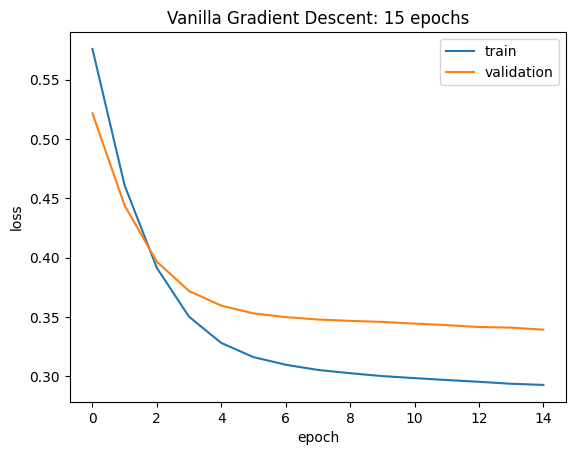

In [ ]:
plt.plot(history_vanilla["loss"], label="train")
plt.plot(history_vanilla["val_loss"], label="validation")

plt.title("Vanilla Gradient Descent: 15 epochs")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()


In [ ]:
model_momentum = build_model()

criterion = nn.BCELoss()
optimizer_momentum = torch.optim.SGD(
    model_momentum.parameters(),
    lr=0.05,
    momentum=0.9
)

In [ ]:
history_momentum = {
    "loss": [],
    "val_loss": []
}

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

In [ ]:
for epoch in range(15):
    model_momentum.train()

    permutation = torch.randperm(X_train_tensor.size(0))
    epoch_loss = 0.0

    for i in range(0, X_train_tensor.size(0), 64):
        indices = permutation[i:i + 64]

        X_batch = X_train_tensor[indices]
        y_batch = y_train_tensor[indices]

        optimizer_momentum.zero_grad()

        y_pred = model_momentum(X_batch)
        loss = criterion(y_pred, y_batch)

        loss.backward()
        optimizer_momentum.step()

        epoch_loss += loss.item() * len(indices)

    epoch_loss /= X_train_tensor.size(0)

    model_momentum.eval()

    with torch.no_grad():
        y_val_pred = model_momentum(X_test_tensor)
        val_loss = criterion(y_val_pred, y_test_tensor).item()

    history_momentum["loss"].append(epoch_loss)
    history_momentum["val_loss"].append(val_loss)

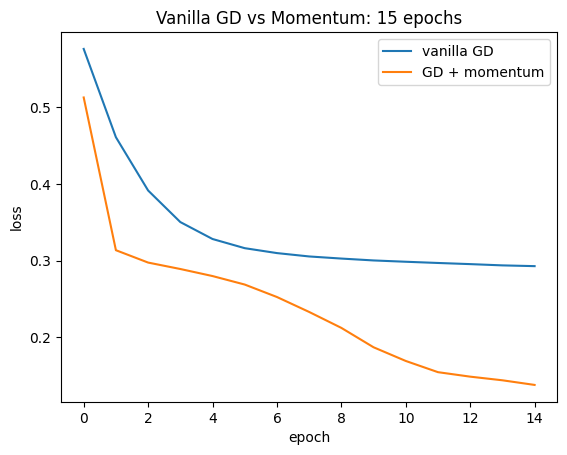

In [ ]:
plt.plot(history_vanilla["loss"], label="vanilla GD")
plt.plot(history_momentum["loss"], label="GD + momentum")

plt.title("Vanilla GD vs Momentum: 15 epochs")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()


In [ ]:
model_adam = build_model()

criterion = nn.BCELoss()
optimizer_adam = torch.optim.Adam(
    model_adam.parameters(),
    lr=0.01,
    betas=(0.9, 0.999)
)


history_adam = {
    "loss": [],
    "val_loss": []
}

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

for epoch in range(15):
    model_adam.train()

    permutation = torch.randperm(X_train_tensor.size(0))
    epoch_loss = 0.0

    for i in range(0, X_train_tensor.size(0), 64):
        indices = permutation[i:i + 64]

        X_batch = X_train_tensor[indices]
        y_batch = y_train_tensor[indices]

        optimizer_adam.zero_grad()

        y_pred = model_adam(X_batch)
        loss = criterion(y_pred, y_batch)

        loss.backward()
        optimizer_adam.step()

        epoch_loss += loss.item() * len(indices)

    epoch_loss /= X_train_tensor.size(0)

    model_adam.eval()

    with torch.no_grad():
        y_val_pred = model_adam(X_test_tensor)
        val_loss = criterion(y_val_pred, y_test_tensor).item()

    history_adam["loss"].append(epoch_loss)
    history_adam["val_loss"].append(val_loss)

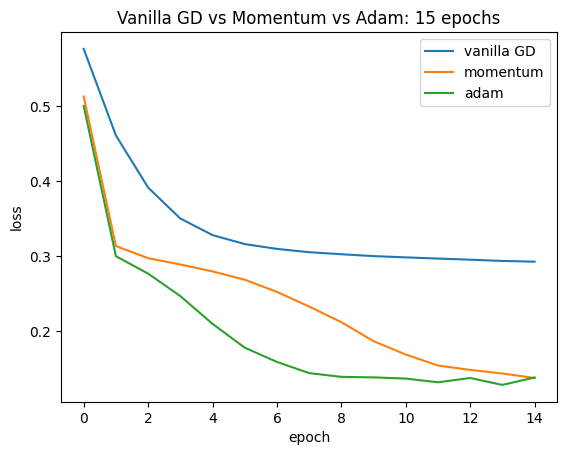

In [ ]:
plt.plot(history_vanilla["loss"], label="vanilla GD")
plt.plot(history_momentum["loss"], label="momentum")
plt.plot(history_adam["loss"], label="adam")

plt.title("Vanilla GD vs Momentum vs Adam: 15 epochs")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()